In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('CO2_emission.csv', encoding='ISO-8859-1')

data.describe()
data.info()
data.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 35 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    215 non-null    object 
 1   country_code    215 non-null    object 
 2   Region          215 non-null    object 
 3   Indicator Name  215 non-null    object 
 4   1990            185 non-null    float64
 5   1991            186 non-null    float64
 6   1992            189 non-null    float64
 7   1993            189 non-null    float64
 8   1994            189 non-null    float64
 9   1995            190 non-null    float64
 10  1996            190 non-null    float64
 11  1997            190 non-null    float64
 12  1998            189 non-null    float64
 13  1999            189 non-null    float64
 14  2000            190 non-null    float64
 15  2001            190 non-null    float64
 16  2002            191 non-null    float64
 17  2003            191 non-null    flo

Index(['Country Name', 'country_code', 'Region', 'Indicator Name', '1990',
       '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999',
       '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008',
       '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017',
       '2018', '2019', '2019.1'],
      dtype='object')

In [4]:
# Data Preparation
# Melt the dataset to have years as a single column
data_melted = data.melt(id_vars=['Country Name', 'country_code', 'Region', 'Indicator Name'], 
                        var_name='Year', value_name='CO2 Emissions')

# Convert Year to numeric, forcing errors to NaN, then drop NaN values
data_melted['Year'] = pd.to_numeric(data_melted['Year'], errors='coerce')
data_melted = data_melted.dropna(subset=['Year'])

# Convert Year to integer
data_melted['Year'] = data_melted['Year'].astype(int)

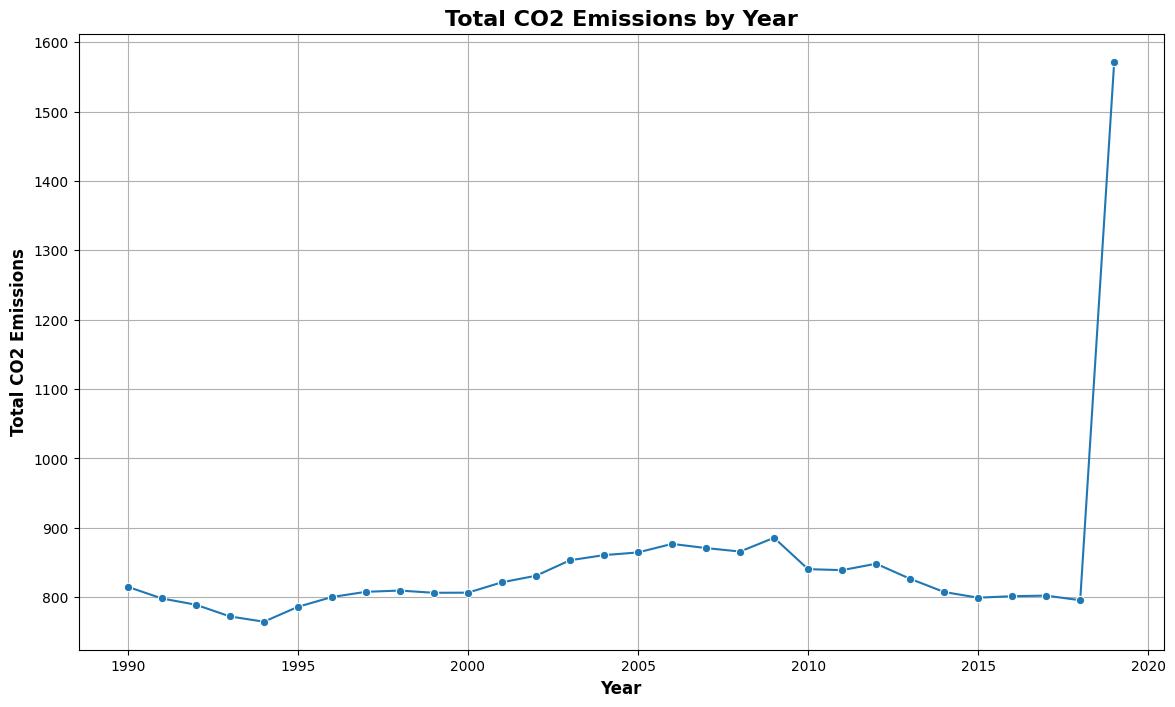

In [5]:
# Total CO2 Emissions by Year
plt.figure(figsize=(14, 8))
total_emissions_by_year = data_melted.groupby('Year')['CO2 Emissions'].sum()
sns.lineplot(x=total_emissions_by_year.index, y=total_emissions_by_year.values, marker='o')
plt.title('Total CO2 Emissions by Year', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Total CO2 Emissions', fontsize=12, fontweight='bold')
plt.grid(True)
plt.show()

/var/folders/03/q36rn1_s5sb399lxs7gjqt500000gn/T/ipykernel_15664/3582486220.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=emissions_by_region.index, y=emissions_by_region.values, palette='muted')


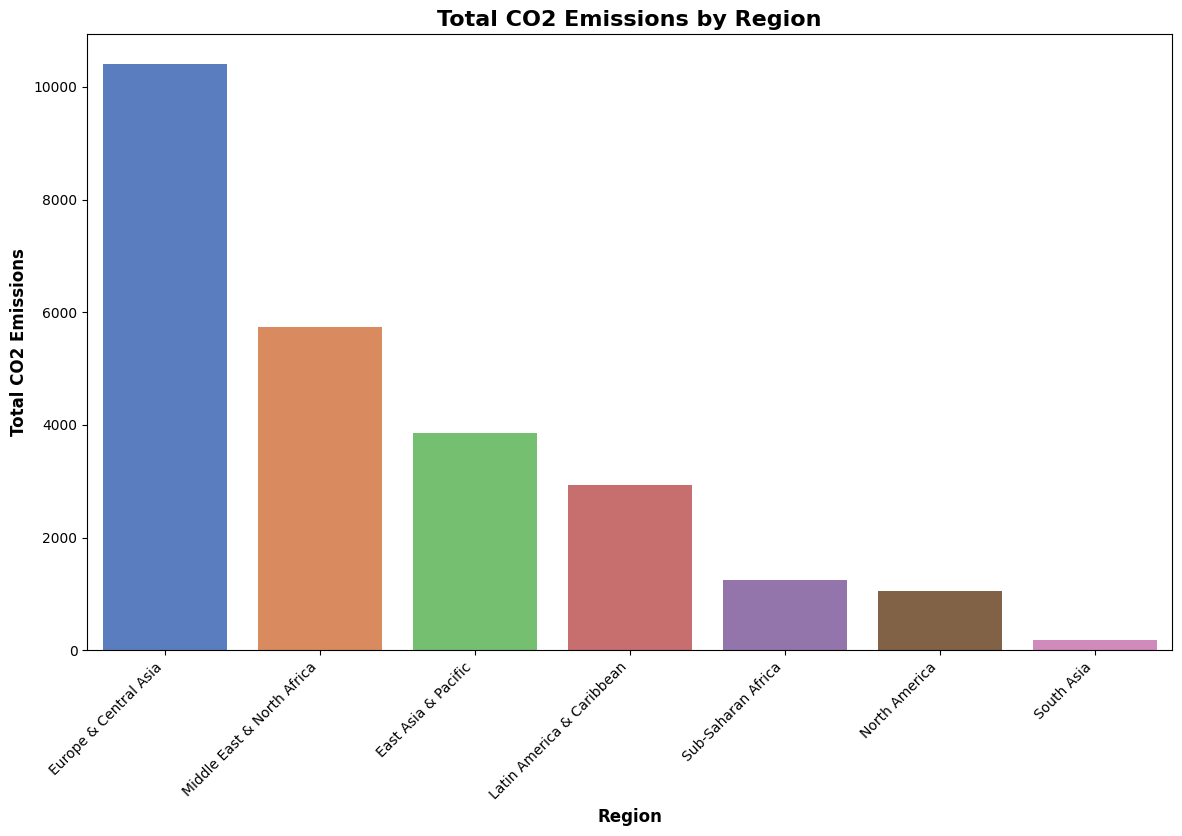

In [6]:
# CO2 Emissions by Region
plt.figure(figsize=(14, 8))
emissions_by_region = data_melted.groupby('Region')['CO2 Emissions'].sum().sort_values(ascending=False)
sns.barplot(x=emissions_by_region.index, y=emissions_by_region.values, palette='muted')
plt.title('Total CO2 Emissions by Region', fontsize=16, fontweight='bold')
plt.xlabel('Region', fontsize=12, fontweight='bold')
plt.ylabel('Total CO2 Emissions', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.show()

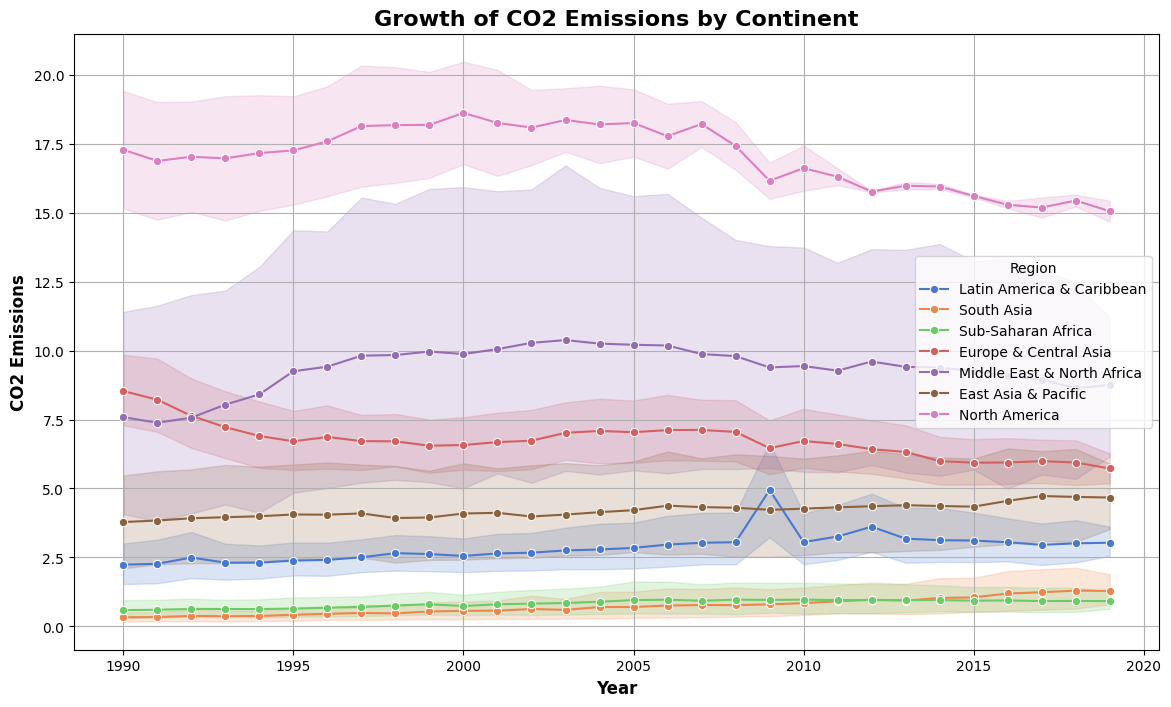

In [7]:
# Growth of CO2 Emissions by Continent
plt.figure(figsize=(14, 8))
sns.lineplot(data=data_melted, x='Year', y='CO2 Emissions', hue='Region', marker='o', palette='muted')
plt.title('Growth of CO2 Emissions by Continent', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('CO2 Emissions', fontsize=12, fontweight='bold')
plt.legend(title='Region')
plt.grid(True)
plt.show()

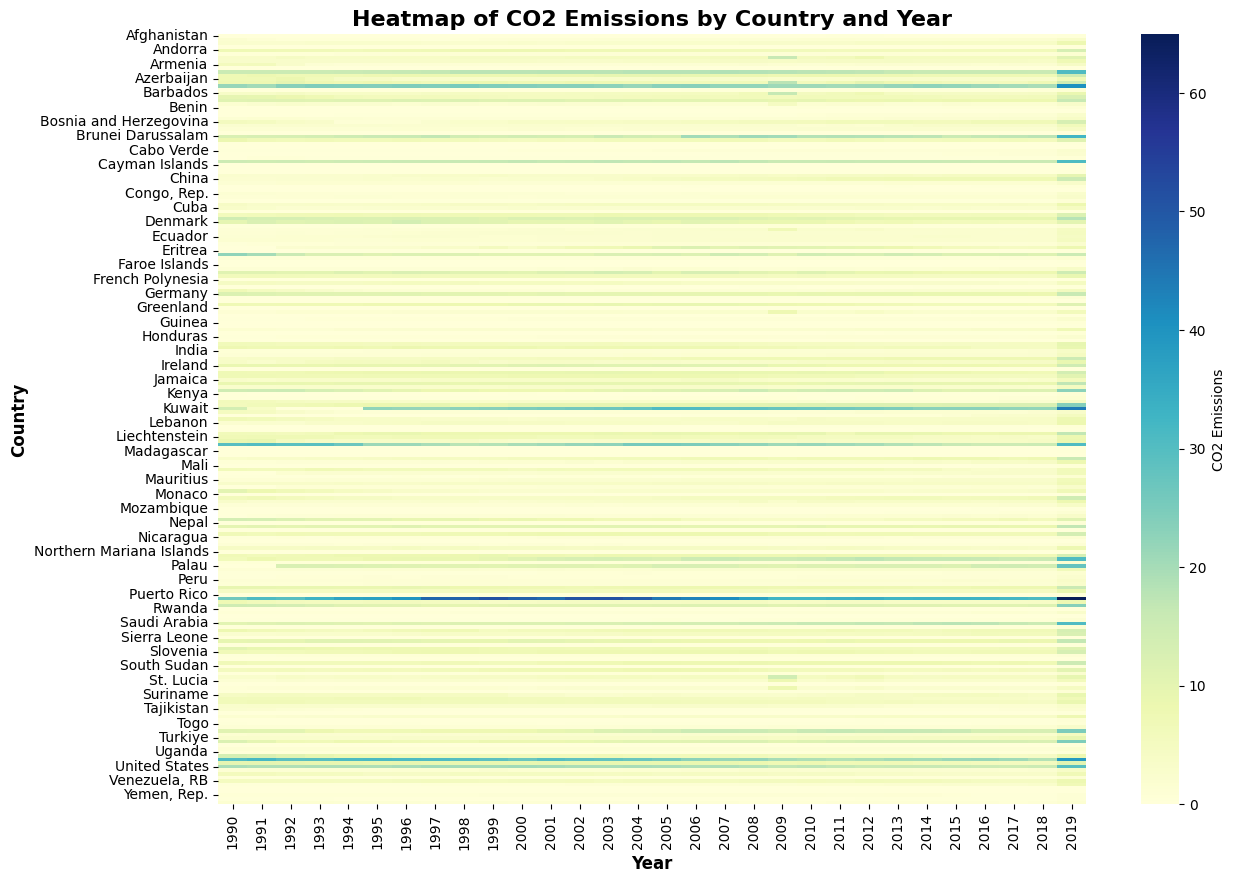

In [8]:
# Heatmap of CO2 Emissions
plt.figure(figsize=(14, 10))
pivot_table = data_melted.pivot_table(index='Country Name', columns='Year', values='CO2 Emissions', aggfunc='sum', fill_value=0)
sns.heatmap(pivot_table, cmap='YlGnBu', cbar_kws={'label': 'CO2 Emissions'})
plt.title('Heatmap of CO2 Emissions by Country and Year', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Country', fontsize=12, fontweight='bold')
plt.show()

/var/folders/03/q36rn1_s5sb399lxs7gjqt500000gn/T/ipykernel_15664/2675920687.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_20_countries.values, y=top_20_countries.index, palette='muted')


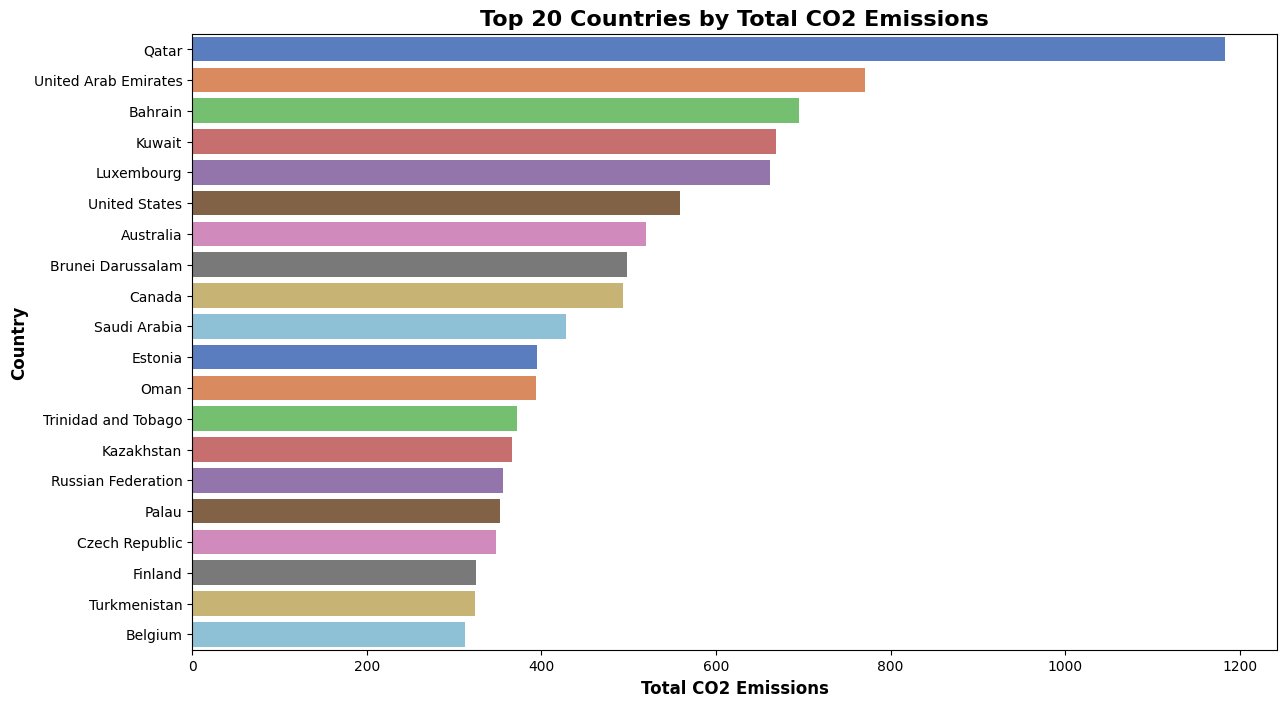

In [9]:
# Calculate the total CO2 emissions for each country
total_emissions_by_country = data_melted.groupby('Country Name')['CO2 Emissions'].sum()

# Sort the countries by their total CO2 emissions and select the top 20
top_20_countries = total_emissions_by_country.sort_values(ascending=False).head(20)

# Plotting the top 20 countries by CO2 emissions
plt.figure(figsize=(14, 8))
sns.barplot(x=top_20_countries.values, y=top_20_countries.index, palette='muted')
plt.title('Top 20 Countries by Total CO2 Emissions', fontsize=16, fontweight='bold')
plt.xlabel('Total CO2 Emissions', fontsize=12, fontweight='bold')
plt.ylabel('Country', fontsize=12, fontweight='bold')
plt.show()

/var/folders/03/q36rn1_s5sb399lxs7gjqt500000gn/T/ipykernel_15664/162452135.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='CO2 Emissions', y='Country Name', data=top_5_countries, ax=axes[i], palette='muted')
/var/folders/03/q36rn1_s5sb399lxs7gjqt500000gn/T/ipykernel_15664/162452135.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='CO2 Emissions', y='Country Name', data=top_5_countries, ax=axes[i], palette='muted')
/var/folders/03/q36rn1_s5sb399lxs7gjqt500000gn/T/ipykernel_15664/162452135.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

 

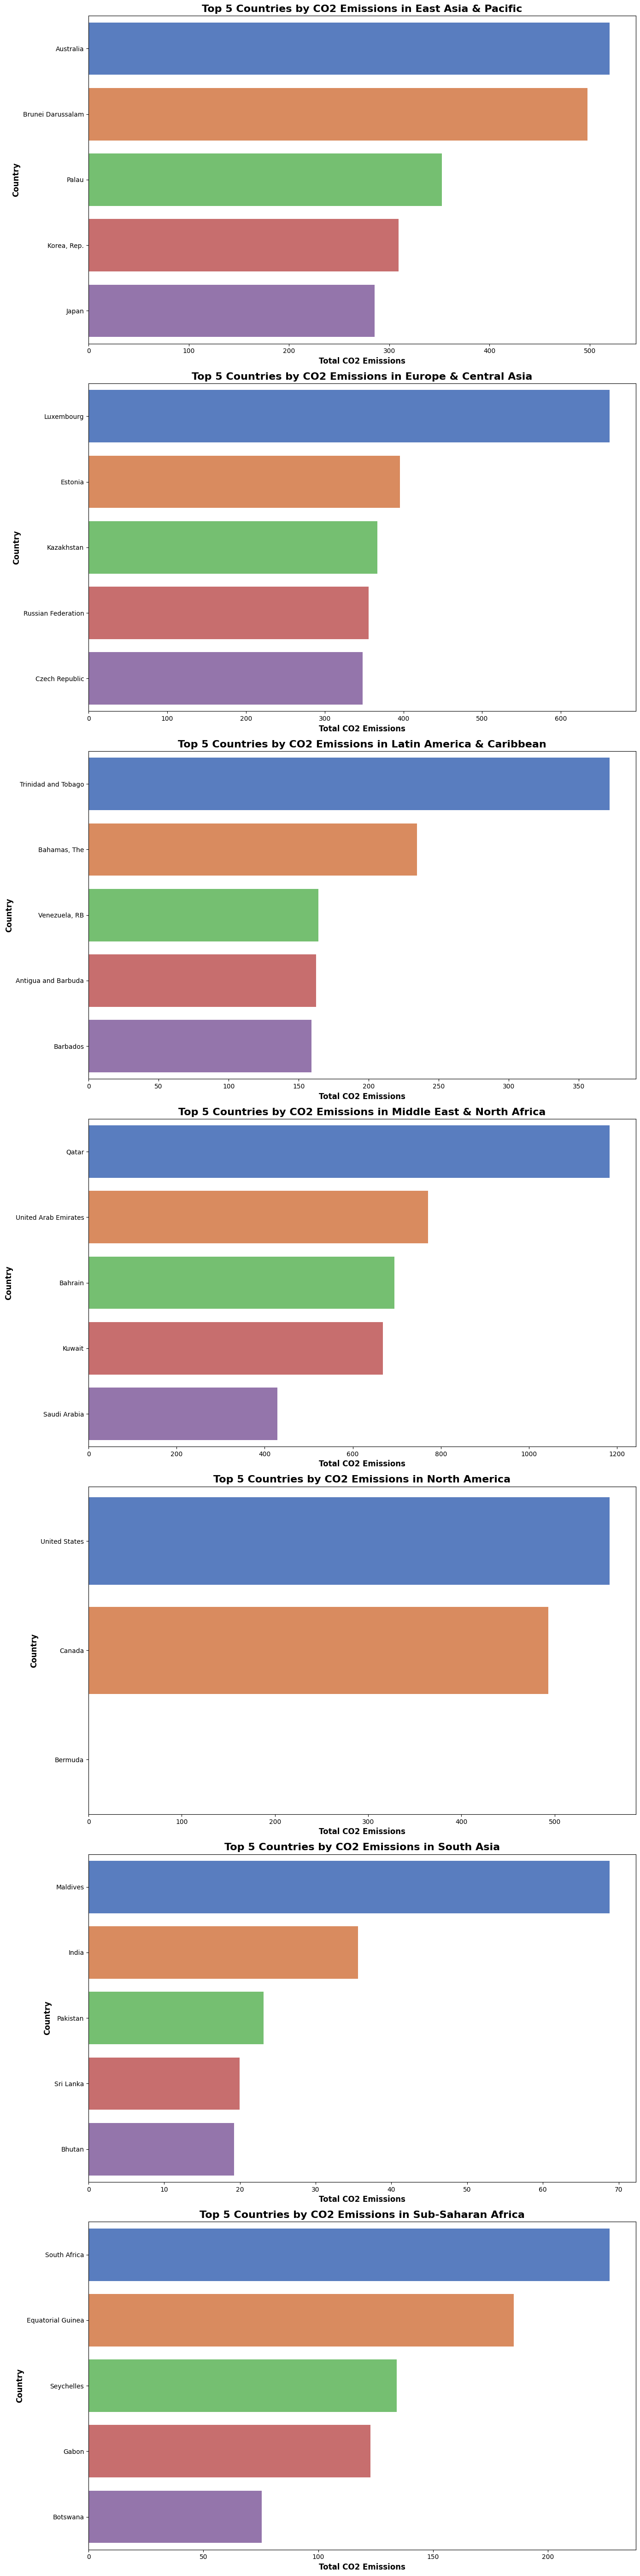

In [10]:
# Calculate the total CO2 emissions for each country
total_emissions_by_country = data_melted.groupby(['Region', 'Country Name'])['CO2 Emissions'].sum().reset_index()

# Get the unique regions
regions = total_emissions_by_country['Region'].unique()

# Create subplots for each region
fig, axes = plt.subplots(nrows=len(regions), ncols=1, figsize=(14, 8 * len(regions)))

# Plot the top 5 countries for each region
for i, region in enumerate(regions):
    # Filter data for the region
    region_data = total_emissions_by_country[total_emissions_by_country['Region'] == region]
    
    # Sort the countries by total CO2 emissions and select the top 5
    top_5_countries = region_data.sort_values(by='CO2 Emissions', ascending=False).head(5)
    
    # Plot the data
    sns.barplot(x='CO2 Emissions', y='Country Name', data=top_5_countries, ax=axes[i], palette='muted')
    axes[i].set_title(f'Top 5 Countries by CO2 Emissions in {region}', fontsize=16, fontweight='bold')
    axes[i].set_xlabel('Total CO2 Emissions', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Country', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()